# LEVEL 2 — TASK 1: HOUSE PRICE PREDICTION USING LINEAR REGRESSION

## 1. Project Overview

The objective of this project is to build a machine learning model that predicts residential house prices using the Ames Housing dataset from Kaggle.

The project covers data exploration, data cleaning, feature selection, categorical encoding, correlation analysis, model training, evaluation, visualization, and model interpretation.

## Objectives

- Perform Exploratory Data Analysis (EDA).
- Inspect missing values and descriptive statistics.
- Understand the distribution of house prices.
- Select relevant features and explain their importance.
- Handle missing values and encode categorical variables using One-Hot Encoding.
- Analyze correlations between numerical features and house prices.
- Split the dataset into 80% training and 20% testing data.
- Train a Linear Regression model.
- Evaluate the model using MSE, RMSE, and R² score.
- Visualize actual versus predicted prices.
- Analyze residuals and regression coefficients.
- Compare Linear Regression with Ridge Regression.

## Technology Stack

Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, and Jupyter Notebook.

## Dataset

Source: Kaggle — House Prices: Advanced Regression Techniques

Dataset file: train.csv

Target variable: SalePrice

## 2. Installing Required Libraries

Install the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 3. Importing Libraries

Import the required libraries and functions for data analysis, visualizations, data preprocessing, Linear Regression, Ridge Regression, and model evaluation.

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 4. Loading the Dataset

Load train.csv from the data folder. This dataset contains property characteristics and the actual sale price, which will be used as the target variable.

Inspect the dataset shape, column names, first five rows, and data types to understand its structure.

In [3]:
DATA_DIR = Path("data")
file_path = DATA_DIR / "train.csv"

if not file_path.exists():
    raise FileNotFoundError(
        "train.csv was not found. Place it inside the data folder "
        "within the House-Price-Prediction project."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (1460, 81)

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorch

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 1

### Dataset Overview — Analysis

The dataset contains property-related information and the target variable SalePrice.

Numerical columns describe measurements such as lot area, living area, number of rooms, and construction year. Categorical columns describe characteristics such as neighborhood, building type, and zoning.

The dataset shape and column names help identify the available observations and features before cleaning and model development.

## 5. Data Quality Assessment

Check the dataset for missing values and duplicate records. Missing values can affect model training, while duplicate records may introduce repeated information into the analysis.

The missing-value counts will help determine which preprocessing methods are required.

In [4]:
print("Missing values by column:")

missing_counts = df.isnull().sum().sort_values(ascending=False)

display(
    missing_counts[missing_counts > 0]
    .to_frame("Missing Values")
)

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print("\nColumns with the highest missing percentages:")
display(
    missing_percentage[missing_percentage > 0]
    .head(15)
    .to_frame("Missing Percentage")
    .round(2)
)

Missing values by column:


,Missing Values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


Total missing values: 7829
Duplicate rows: 0

Columns with the highest missing percentages:


,Missing Percentage
PoolQC,99.52
MiscFeature,96.30
Alley,93.77
Fence,80.75
MasVnrType,59.73
FireplaceQu,47.26
LotFrontage,17.74
GarageQual,5.55
GarageFinish,5.55
GarageType,5.55


In [5]:
print("Missing values by column:")

missing_counts = df.isnull().sum().sort_values(ascending=False)

display(
    missing_counts[missing_counts > 0]
    .to_frame("Missing Values")
)

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print("\nColumns with the highest missing percentages:")
display(
    missing_percentage[missing_percentage > 0]
    .head(15)
    .to_frame("Missing Percentage")
    .round(2)
)

Missing values by column:


,Missing Values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


Total missing values: 7829
Duplicate rows: 0

Columns with the highest missing percentages:


,Missing Percentage
PoolQC,99.52
MiscFeature,96.30
Alley,93.77
Fence,80.75
MasVnrType,59.73
FireplaceQu,47.26
LotFrontage,17.74
GarageQual,5.55
GarageFinish,5.55
GarageType,5.55


### Data Quality — Analysis

The missing-value report identifies columns that require attention before model training.

Some categorical columns may have missing values because a property does not have a particular feature, such as a pool or alley. Other missing values may represent information that was not recorded.

We will use median imputation for numerical columns and most-frequent-value imputation for categorical columns. These transformations will be fitted using training data only.

Duplicate records will be investigated before deciding whether any removal is necessary.

## 6. Descriptive Statistics

Descriptive statistics summarize the numerical variables using count, mean, standard deviation, minimum, quartiles, and maximum.

Categorical statistics summarize the number of unique values and the most frequent categories.

In [6]:
print("Numerical descriptive statistics:")
display(df.describe().T.round(2))

print("\nCategorical descriptive statistics:")
display(df.describe(include="object").T)

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0



Categorical descriptive statistics:


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### Descriptive Statistics — Analysis

The descriptive statistics help us understand the range and variation of house characteristics.

The mean and median help describe typical values, while minimum and maximum values can identify unusual observations that deserve further investigation.

Large differences in feature ranges are expected because variables such as area, year built, and quality ratings use different units.

## 7. Distribution of House Prices

SalePrice is the target variable that the machine learning model will predict.

A histogram displays the distribution of house prices, while a boxplot helps identify unusually low or high prices. Understanding the target distribution is important before training the model.

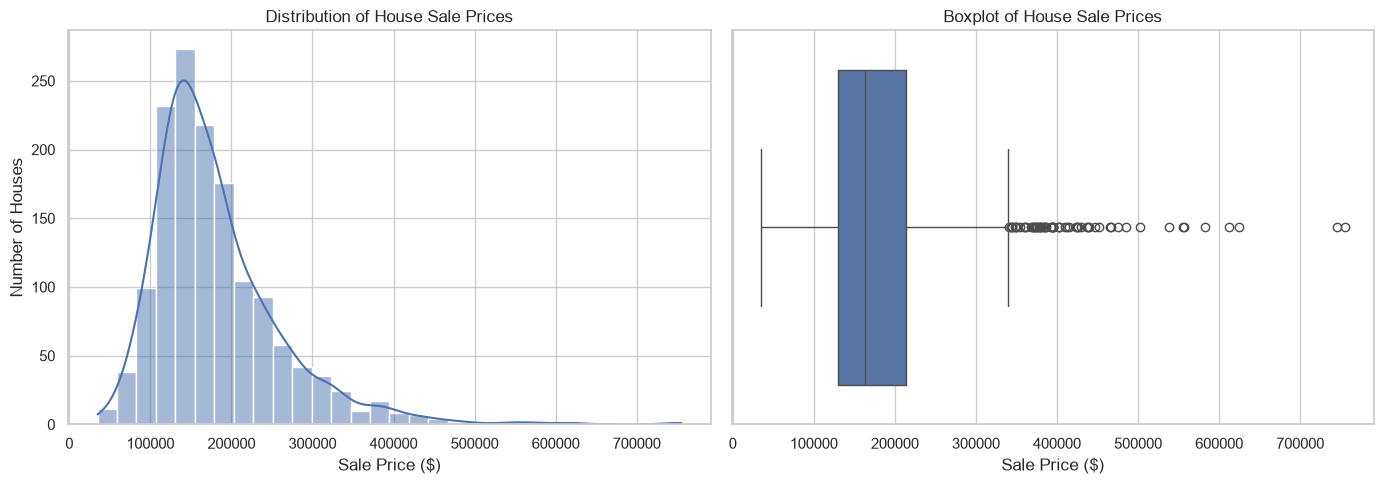

Minimum sale price: 34900
Maximum sale price: 755000
Mean sale price: 180921.2
Median sale price: 163000.0
Standard deviation: 79442.5


In [8]:
if "SalePrice" not in df.columns:
    raise KeyError("SalePrice column was not found in the dataset.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of House Sale Prices")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Number of Houses")

sns.boxplot(
    x=df["SalePrice"],
    ax=axes[1]
)

axes[1].set_title("Boxplot of House Sale Prices")
axes[1].set_xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

print("Minimum sale price:", df["SalePrice"].min())
print("Maximum sale price:", df["SalePrice"].max())
print("Mean sale price:", round(df["SalePrice"].mean(), 2))
print("Median sale price:", round(df["SalePrice"].median(), 2))
print("Standard deviation:", round(df["SalePrice"].std(), 2))

### SalePrice Distribution — Analysis

Use the histogram and boxplot to describe the actual distribution shown by your dataset.

Check whether the histogram is symmetrical or right-skewed. If the mean is greater than the median, expensive properties may be pulling the average upward.

The boxplot can highlight potential outliers. These observations should not automatically be removed because expensive properties may represent legitimate sales.

## 8. Feature Selection and Reasoning

Feature selection helps identify variables that may provide useful information for predicting house prices.

The following features are considered relevant:

- OverallQual: represents the overall material and finish quality of the property.
- GrLivArea: measures above-ground living area.
- LotArea: describes the size of the property lot.
- TotalBsmtSF: represents the total basement area.
- GarageCars: indicates the garage's car capacity.
- YearBuilt: indicates the original construction year.
- Neighborhood: describes the property's location.
- FullBath: indicates the number of full bathrooms above ground.
- BedroomAbvGr: indicates the number of bedrooms above ground.

These features represent property size, quality, age, facilities, and location, which may be associated with sale price.

We will begin with the available features except Id, which is a record identifier rather than a meaningful property characteristic. The correlation analysis and fitted model coefficients will help us examine the relationships between the features and SalePrice.

The selected features are potential predictors, not proof of causal effects.

## 9. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between numerical variables.

A positive correlation indicates that two variables tend to increase together, while a negative correlation indicates that one tends to decrease as the other increases.

We will identify the numerical features most correlated with SalePrice and visualize their correlations using a heatmap.

Top 15 numerical features correlated with SalePrice:


,Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


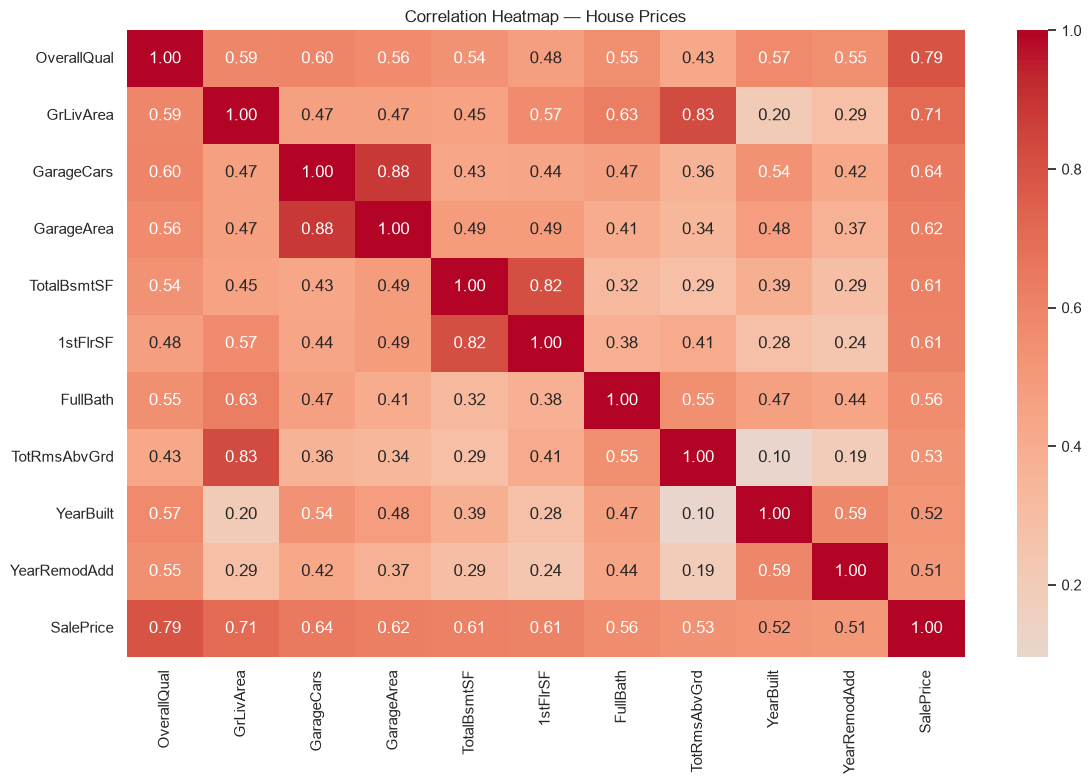

In [9]:
numeric_df = df.select_dtypes(include=np.number)

correlation_with_price = (
    numeric_df.corr(numeric_only=True)["SalePrice"]
    .drop(labels=["SalePrice", "Id"], errors="ignore")
    .sort_values(key=abs, ascending=False)
)

print("Top 15 numerical features correlated with SalePrice:")
display(
    correlation_with_price.head(15).to_frame("Correlation")
)

top_features = correlation_with_price.head(10).index.tolist()
heatmap_columns = top_features + ["SalePrice"]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[heatmap_columns].corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap — House Prices")
plt.tight_layout()
plt.show()

### Correlation Heatmap — Analysis

Use the correlation table to identify the numerical features with the strongest positive and negative relationships with SalePrice.

A positive correlation means higher values tend to be associated with higher sale prices. A negative correlation means higher values tend to be associated with lower sale prices.

Correlation measures linear association, not causation. Categorical variables such as Neighborhood are not included in this numerical-only heatmap, but they will be encoded and included in model training.

## 10. Separating Features and Target

Separate SalePrice as the target variable and the remaining property characteristics as input features.

The Id column will be removed because it identifies records rather than describing a meaningful property characteristic. Numerical and categorical columns will be processed separately.

In [10]:
X = df.drop(columns=["SalePrice", "Id"], errors="ignore").copy()
y = df["SalePrice"].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of input features:", X.shape[1])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical feature examples:")
print(numeric_features[:10])

print("\nCategorical feature examples:")
print(categorical_features[:10])

Number of input features: 79
Numerical features: 36
Categorical features: 43

Numerical feature examples:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2']

Categorical feature examples:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1']


## 11. Train-Test Split (80/20)

Split the dataset into 80% training data and 20% testing data.

The training data is used to fit the model. The testing data is reserved for evaluating how well the model predicts prices for observations it has not seen during training.

We use a fixed random state to make the split reproducible.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Total observations:", len(X))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print(
    "Training percentage:",
    round(len(X_train) / len(X) * 100, 2), "%"
)

print(
    "Testing percentage:",
    round(len(X_test) / len(X) * 100, 2), "%"
)

Total observations: 1460
Training observations: 1168
Testing observations: 292
Training percentage: 80.0 %
Testing percentage: 20.0 %


### Train-Test Split — Analysis

The dataset has been divided into 80% training observations and 20% testing observations.

The training set is used to learn the relationships between property characteristics and SalePrice. The testing set provides an independent evaluation of model performance.

All imputation, scaling, and categorical encoding will be fitted within a pipeline using training data only to prevent data leakage.

## 12. Data Preprocessing and One-Hot Encoding

Numerical columns will be imputed using their median values and standardized using StandardScaler.

Categorical columns will be imputed using their most frequent values and transformed using One-Hot Encoding.

One-Hot Encoding converts categories into binary indicator columns so that a regression model can process categorical information. The handle_unknown="ignore" setting allows the model to handle categories that appear in testing data but were not present in training data.

A ColumnTransformer and Pipeline ensure that preprocessing is fitted on training data and applied consistently to testing data.

In [13]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numerical preprocessing: median imputation + scaling")
print("Categorical preprocessing: most-frequent imputation + One-Hot Encoding")
print("Preprocessing pipeline created successfully!")

Numerical preprocessing: median imputation + scaling
Categorical preprocessing: most-frequent imputation + One-Hot Encoding
Preprocessing pipeline created successfully!


## 13. Training the Linear Regression Model

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value.

It learns coefficients for the input features to minimize the sum of squared differences between actual and predicted sale prices.

The model will be combined with the preprocessing pipeline so missing values, scaling, and categorical encoding are handled consistently.

In [14]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

linear_predictions = linear_model.predict(X_test)

print("\nFirst 10 predictions:")
display(
    pd.DataFrame({
        "Actual SalePrice": y_test.iloc[:10].to_numpy(),
        "Predicted SalePrice": linear_predictions[:10]
    }).round(2)
)

Linear Regression model trained successfully!

First 10 predictions:


,Actual SalePrice,Predicted SalePrice
0,154500,157607.48
1,325000,348503.22
2,115000,86482.21
3,159000,174161.91
4,315500,316991.53
5,75500,66792.97
6,311500,236152.74
7,146000,145997.17
8,84500,57578.21
9,135500,154054.07


### Linear Regression — Analysis

The model has been fitted using the training dataset.

It uses numerical and encoded categorical property characteristics to estimate house prices. The first predictions provide an initial comparison between actual and estimated values.

The model's effectiveness will be assessed using MSE, RMSE, and R² on the held-out testing dataset.

## 14. Model Evaluation

Evaluate the Linear Regression model using three metrics:

- Mean Squared Error (MSE): the average squared difference between actual and predicted prices. Lower values are better.
- Root Mean Squared Error (RMSE): the square root of MSE. It is expressed in the same units as the target, dollars. Lower values are better.
- R² Score: measures how much variation in the target is explained by the model. A score closer to 1 is generally better; a negative score indicates performance worse than a baseline that predicts the training-set mean.

All metrics are calculated using testing data that was not used to fit the model.

In [15]:
mse = mean_squared_error(y_test, linear_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_predictions)

evaluation_df = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "R² Score"],
    "Value": [mse, rmse, r2]
})

print("Linear Regression Evaluation Results:")
display(evaluation_df.round(4))

print(f"MSE: ${mse:,.2f} squared")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Linear Regression Evaluation Results:


,Metric,Value
0,MSE,8.687010e+08
1,RMSE,2.947373e+04
2,R² Score,8.867000e-01


MSE: $868,700,970.56 squared
RMSE: $29,473.73
R² Score: 0.8867


### Model Evaluation — Analysis

Interpret the actual scores produced by the notebook.

- A lower MSE indicates smaller average squared prediction errors.
- A lower RMSE indicates smaller typical prediction errors in dollar units, though it gives extra weight to large errors.
- An R² score closer to 1 indicates that the model explains a larger proportion of the variation in testing prices.

The scores should be considered together. No performance value should be assumed before running the notebook.

## 15. Actual vs Predicted House Prices

Compare the actual sale prices with the prices predicted by the Linear Regression model.

The dashed diagonal represents perfect predictions. Points closer to this line indicate more accurate predictions, while points farther away represent larger prediction errors.

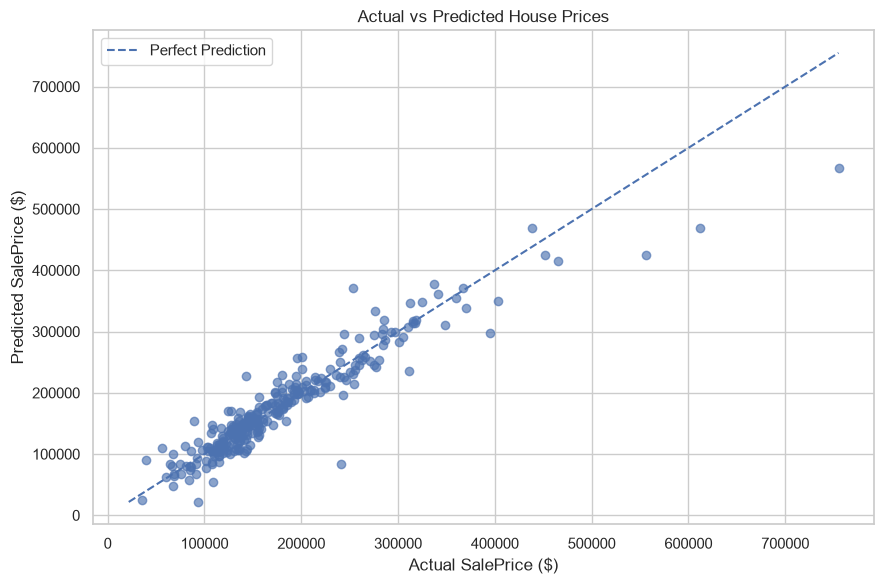

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.65
)

lower = min(y_test.min(), linear_predictions.min())
upper = max(y_test.max(), linear_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

### Actual vs Predicted — Analysis

Points close to the diagonal line indicate that predicted prices are close to actual prices.

Points far from the line indicate larger prediction errors. Examine whether the model appears to overestimate or underestimate some properties, particularly at higher prices.

The scatter plot complements the numerical evaluation metrics by showing how prediction errors vary across the price range.

## 16. Residual Plot

A residual is calculated as:

Residual = Actual SalePrice - Predicted SalePrice

Residual analysis helps determine whether the model's errors show systematic patterns.

A reasonably good residual plot should show points scattered around zero without a strong curve or other systematic pattern. A funnel shape may suggest that error variance changes with predicted price.

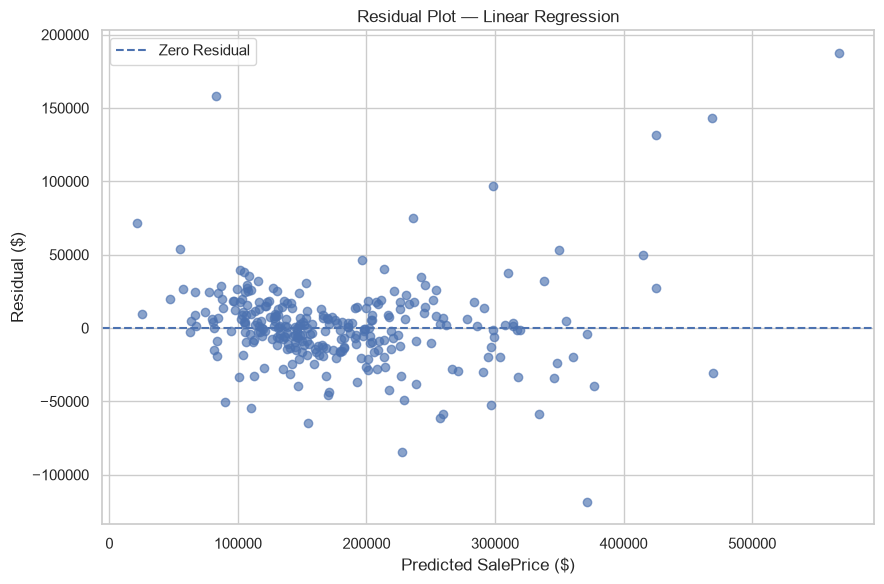

Mean residual: 1382.06
Minimum residual: -118537.29
Maximum residual: 187537.17


In [17]:
residuals = y_test.to_numpy() - linear_predictions

plt.figure(figsize=(9, 6))

plt.scatter(
    linear_predictions,
    residuals,
    alpha=0.65
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Zero Residual"
)

plt.title("Residual Plot — Linear Regression")
plt.xlabel("Predicted SalePrice ($)")
plt.ylabel("Residual ($)")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))
print("Minimum residual:", round(residuals.min(), 2))
print("Maximum residual:", round(residuals.max(), 2))

### Residual Analysis — Interpretation

Residuals above zero indicate underprediction because the actual price is higher than the predicted price. Residuals below zero indicate overprediction.

Check whether residuals are randomly scattered around zero or show a systematic pattern. A curve can suggest a nonlinear relationship, while a funnel shape may indicate non-constant error variance.

Residuals do not need to be perfectly random in real-world data. Any visible pattern should be documented as a potential limitation of the model.

## 17. Regression Coefficient Analysis

Regression coefficients describe how the fitted model's prediction changes with each feature, holding other model inputs constant.

- Positive coefficients increase the predicted price.
- Negative coefficients decrease the predicted price.
- Numerical features were standardized, so their coefficients correspond to a one-standard-deviation change.
- One-Hot Encoded category coefficients are interpreted relative to the reference category used by the encoder.

The coefficient analysis identifies the features with the largest positive and negative coefficients. These relationships are model-based associations and do not establish causation.

Top 15 coefficients by absolute magnitude:


,Feature,Coefficient,Absolute Coefficient
124,categorical__RoofMatl_ClyTile,-529469.76,529469.76
101,categorical__Condition2_PosN,-195532.87,195532.87
246,categorical__GarageQual_Ex,136770.61,136770.61
251,categorical__GarageCond_Ex,-126790.53,126790.53
126,categorical__RoofMatl_Metal,124828.82,124828.82
130,categorical__RoofMatl_WdShngl,90138.40,90138.40
100,categorical__Condition2_PosA,83882.34,83882.34
128,categorical__RoofMatl_Tar&Grv,82460.18,82460.18
259,categorical__PoolQC_Ex,79812.79,79812.79
125,categorical__RoofMatl_CompShg,77979.19,77979.19


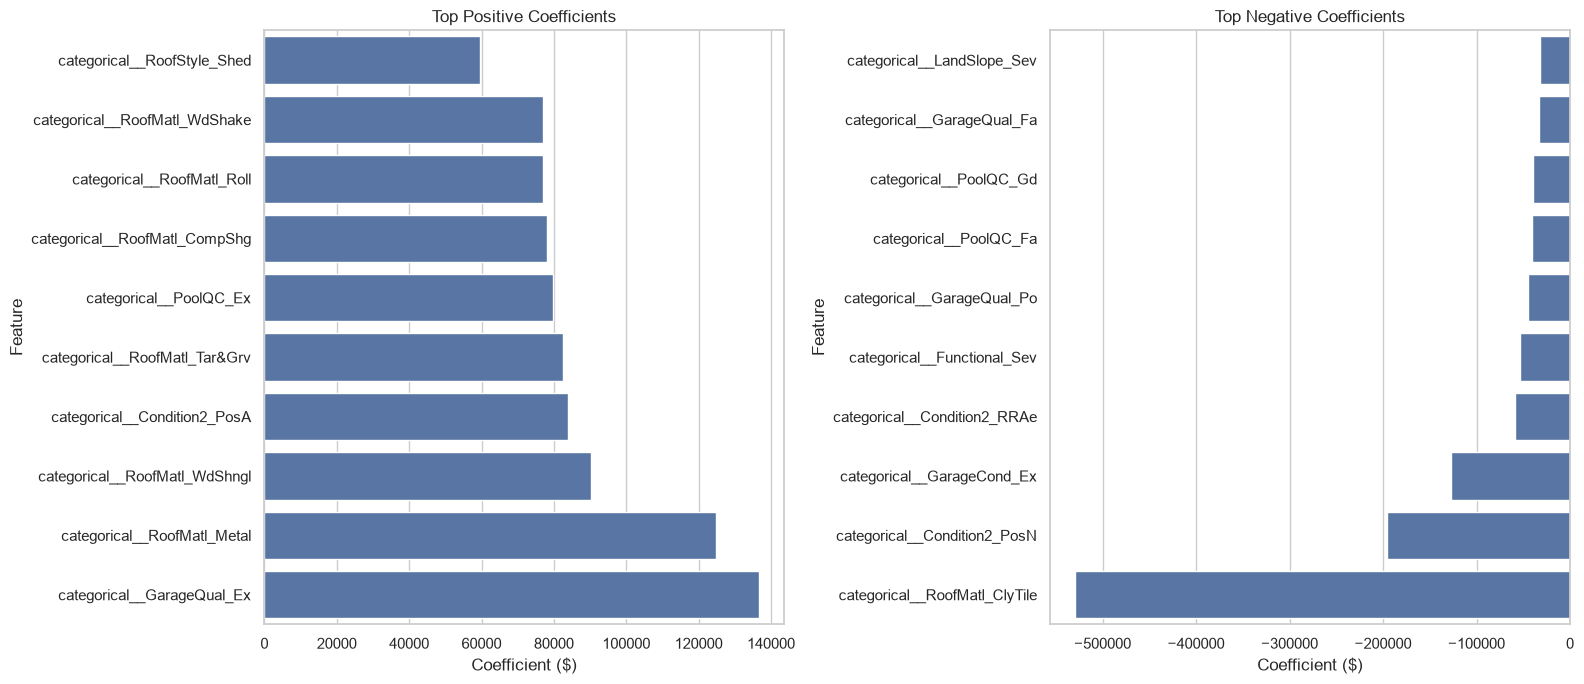

In [18]:
fitted_preprocessor = linear_model.named_steps["preprocessor"]
fitted_regressor = linear_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_regressor.coef_

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print("Top 15 coefficients by absolute magnitude:")
display(coefficient_df.head(15).round(2))

positive_coefficients = (
    coefficient_df[coefficient_df["Coefficient"] > 0]
    .nlargest(10, "Coefficient")
    .sort_values("Coefficient")
)

negative_coefficients = (
    coefficient_df[coefficient_df["Coefficient"] < 0]
    .nsmallest(10, "Coefficient")
    .sort_values("Coefficient", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=positive_coefficients,
    x="Coefficient",
    y="Feature",
    ax=axes[0]
)

axes[0].set_title("Top Positive Coefficients")
axes[0].set_xlabel("Coefficient ($)")

sns.barplot(
    data=negative_coefficients,
    x="Coefficient",
    y="Feature",
    ax=axes[1]
)

axes[1].set_title("Top Negative Coefficients")
axes[1].set_xlabel("Coefficient ($)")

plt.tight_layout()
plt.show()

### Coefficient Analysis — Interpretation

Review the coefficient table and plots to identify the strongest positive and negative coefficients in the fitted model.

A positive coefficient increases the model's prediction, while a negative coefficient decreases it, all else being equal within the model.

Because numerical inputs are standardized, their coefficient magnitudes represent changes associated with one standard deviation in the original feature. Categorical coefficients are relative to a reference category.

Coefficient magnitude alone does not prove that a feature causes house prices to change. Correlated features can also make individual coefficients less stable.

## 18. Bonus: Linear Regression vs Ridge Regression

Ridge Regression is a regularized form of Linear Regression. It adds an L2 penalty to the loss function, discouraging excessively large coefficients.

This can help reduce overfitting when input features are correlated. We will compare both models using the same training data, testing data, and preprocessing steps.

Model Comparison:


,Model,MSE,RMSE,R2 Score
0,Linear Regression,8.687010e+08,29473.7336,0.8867
1,Ridge Regression,9.391864e+08,30646.1481,0.8776


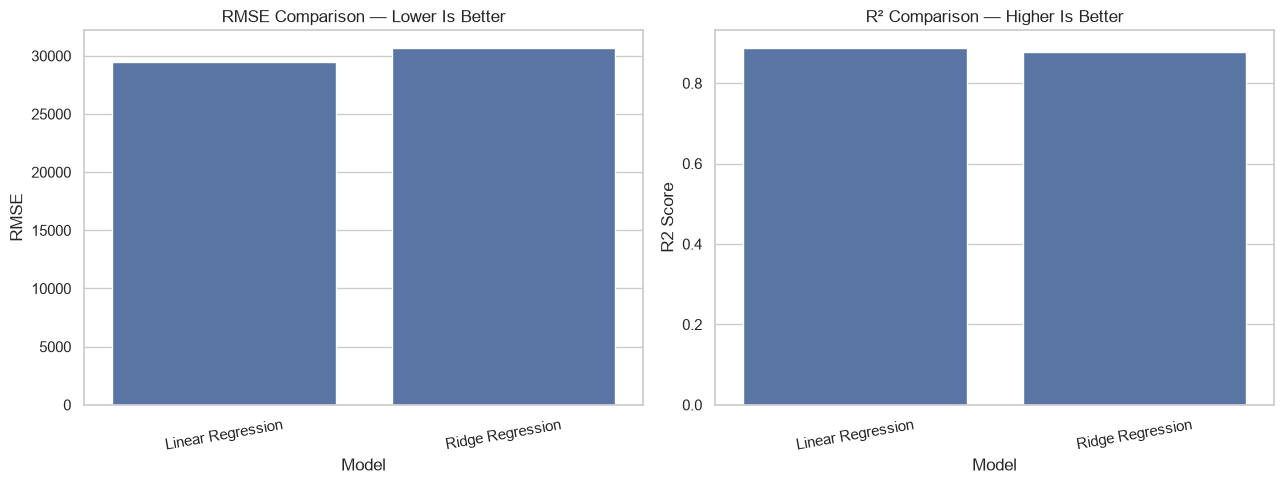

Model with the lowest testing RMSE: Linear Regression


In [19]:
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_predictions)

comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [mse, ridge_mse],
    "RMSE": [rmse, ridge_rmse],
    "R2 Score": [r2, ridge_r2]
})

print("Model Comparison:")
display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE",
    ax=axes[0]
)

axes[0].set_title("RMSE Comparison — Lower Is Better")
axes[0].tick_params(axis="x", rotation=10)

sns.barplot(
    data=comparison_df,
    x="Model",
    y="R2 Score",
    ax=axes[1]
)

axes[1].set_title("R² Comparison — Higher Is Better")
axes[1].tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

best_model_name = comparison_df.loc[
    comparison_df["RMSE"].idxmin(), "Model"
]

print("Model with the lowest testing RMSE:", best_model_name)

### Model Comparison — Interpretation

Compare the testing RMSE and R² scores for Linear Regression and Ridge Regression.

The model with the lower RMSE has smaller root-mean-squared prediction errors on this test split. The model with the higher R² explains more variation in the testing target relative to the baseline.

Ridge Regression is not guaranteed to outperform Linear Regression. The results from this experiment determine which model performs better on the selected test split.

## 19. Exporting Results

Save the model evaluation metrics, testing predictions, residuals, and regression coefficients as CSV files.

These files provide evidence of the completed analysis and can be included in the GitHub repository.

In [20]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model evaluation metrics
comparison_df.to_csv(
    output_dir / "model_evaluation_results.csv",
    index=False
)

# Save actual prices, predictions, and residuals
prediction_results = pd.DataFrame({
    "Actual SalePrice": y_test.to_numpy(),
    "Linear Regression Prediction": linear_predictions,
    "Linear Regression Residual": residuals,
    "Ridge Regression Prediction": ridge_predictions,
    "Ridge Regression Residual": (
        y_test.to_numpy() - ridge_predictions
    )
})

prediction_results.to_csv(
    output_dir / "house_price_predictions.csv",
    index=False
)

# Save Linear Regression coefficients
coefficient_df.to_csv(
    output_dir / "linear_regression_coefficients.csv",
    index=False
)

print("All output files saved successfully!")

for output_file in sorted(output_dir.glob("*.csv")):
    print(output_file)

All output files saved successfully!
output\house_price_predictions.csv
output\linear_regression_coefficients.csv
output\model_evaluation_results.csv


# 20. Conclusion

This project developed a machine learning model to predict residential house prices using the Ames Housing dataset from Kaggle.

The project included exploratory data analysis, missing-value assessment, descriptive statistics, target distribution analysis, feature selection, correlation analysis, and data preprocessing.

Numerical missing values were handled using median imputation, while categorical missing values were handled using most-frequent-value imputation. Categorical features were converted using One-Hot Encoding.

The dataset was divided into 80% training data and 20% testing data. Linear Regression was trained as the main model, and Ridge Regression was evaluated as a regularized alternative.

Both models were evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² score. Actual-versus-predicted plots, residual analysis, and regression coefficients were used to examine model performance and feature relationships.

**Best-performing model:** Insert the model identified by the testing RMSE comparison.

**Key findings:** Insert the important relationships observed in the correlation heatmap, coefficient analysis, and evaluation results.

## Limitations

House prices can depend on market conditions, location, and other factors not fully captured by the available data. Linear Regression may not represent every nonlinear relationship, and performance can vary across different properties.

The model's predictions are estimates, not guaranteed market prices. Correlation and coefficients should not be interpreted as proof of causation.

## Real-World Applications

House price prediction can support preliminary property valuation, real-estate market analysis, pricing decisions, and property investment research.

## References

1. Kaggle — House Prices: Advanced Regression Techniques  
   https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data

2. scikit-learn — LinearRegression  
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

3. scikit-learn — mean_squared_error  
   https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html

4. scikit-learn — r2_score  
   https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

5. scikit-learn — Ridge Regression  
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

**Project:** OIBSIP — Level 2, Task 1  
